In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [3]:
df = pd.read_csv("diabetes_prediction_dataset.csv")
print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)
display(df.head(10))

Dataset loaded successfully!
Dataset Shape: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
5,Female,20.0,0,0,never,27.32,6.6,85,0
6,Female,44.0,0,0,never,19.31,6.5,200,1
7,Female,79.0,0,0,No Info,23.86,5.7,85,0
8,Male,42.0,0,0,never,33.64,4.8,145,0
9,Female,32.0,0,0,never,27.32,5.0,100,0


In [5]:
print("Dataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


In [6]:
print("\nDataset Description:")
display(df.describe())


Dataset Description:


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [7]:
print("\nDataset Columns:")
print(df.columns.tolist())


Dataset Columns:
['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']


In [8]:
print("Missing Values in Each Column:")
print(df.isnull().sum())
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values in Each Column:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

Total Missing Values:
0


In [9]:
print("Before Removing Duplicates:", df.shape)
print("Total Duplicates:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("\nAfter Removing Duplicates:", df.shape)
print("Remaining Duplicates:", df.duplicated().sum())

Before Removing Duplicates: (100000, 9)
Total Duplicates: 3854

After Removing Duplicates: (96146, 9)
Remaining Duplicates: 0


In [10]:
print("Diabetes Class Distribution:")
print(df["diabetes"].value_counts())
print("\nClass Percentages:")
print(df["diabetes"].value_counts(normalize=True) * 100)

Diabetes Class Distribution:
diabetes
0    87664
1     8482
Name: count, dtype: int64

Class Percentages:
diabetes
0    91.178
1     8.822
Name: proportion, dtype: float64


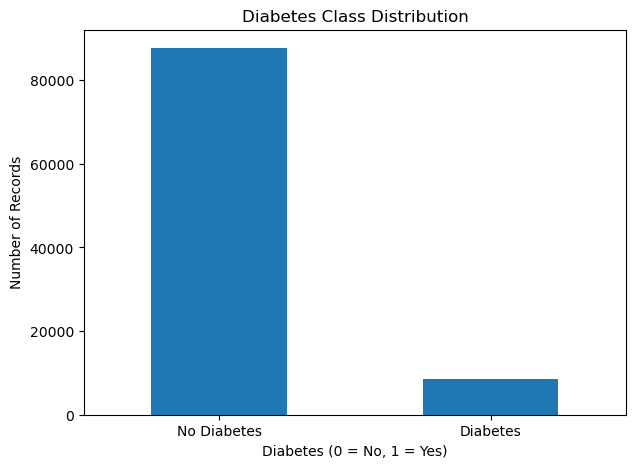

In [11]:
plt.figure(figsize=(7, 5))
df["diabetes"].value_counts().sort_index().plot(
    kind="bar"
)
plt.title("Diabetes Class Distribution")
plt.xlabel("Diabetes (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
plt.xticks([0, 1], ["No Diabetes", "Diabetes"], rotation=0)
plt.show()

In [12]:
X = df.drop("diabetes", axis=1)
y = df["diabetes"].values
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("Target Classes:", np.unique(y))

Features Shape: (96146, 8)
Target Shape: (96146,)
Target Classes: [0 1]


In [18]:
X = df.drop("diabetes", axis=1).copy()
y = df["diabetes"].values

X.columns = X.columns.str.strip()
X = pd.get_dummies(
    X,
    columns=["gender", "smoking_history"]
)
X = X.astype(float)
print("Categorical Encoding Completed!")
print("\nUpdated Features:")
print(X.columns.tolist())
print("\nEncoded Features Shape:", X.shape)
display(X.head())

Categorical Encoding Completed!

Updated Features:
['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'gender_Female', 'gender_Male', 'gender_Other', 'smoking_history_No Info', 'smoking_history_current', 'smoking_history_ever', 'smoking_history_former', 'smoking_history_never', 'smoking_history_not current']

Encoded Features Shape: (96146, 15)


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
0,80.0,0.0,1.0,25.19,6.6,140.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,54.0,0.0,0.0,27.32,6.6,80.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,28.0,0.0,0.0,27.32,5.7,158.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,36.0,0.0,0.0,23.45,5.0,155.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,76.0,1.0,1.0,20.14,4.8,155.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [19]:
np.random.seed(42)
train_indices = []
test_indices = []
for label in np.unique(y):

    class_indices = np.where(y == label)[0]
    np.random.shuffle(class_indices)
    split_point = int(0.8 * len(class_indices))
    train_indices.extend(class_indices[:split_point])
    test_indices.extend(class_indices[split_point:])

train_indices = np.array(train_indices)
test_indices = np.array(test_indices)

X = X.values.astype(float)

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

print("Dataset Splitting Completed")

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nTraining Class Distribution:")
print(pd.Series(y_train).value_counts())

print("\nTesting Class Distribution:")
print(pd.Series(y_test).value_counts())

Dataset Splitting Completed
Training Records: 76916
Testing Records: 19230

Training Class Distribution:
0    70131
1     6785
Name: count, dtype: int64

Testing Class Distribution:
0    17533
1     1697
Name: count, dtype: int64


In [20]:
np.random.seed(42)
class_0 = np.where(y_train == 0)[0]
class_1 = np.where(y_train == 1)[0]

class_0_selected = np.random.choice(
    class_0,
    size=len(class_1),
    replace=False
)
balanced_indices = np.concatenate([
    class_0_selected,
    class_1
])

np.random.shuffle(balanced_indices)
X_train = X_train[balanced_indices]
y_train = y_train[balanced_indices]
print("Training Data Balanced Successfully")
print("\nClass 0:", np.sum(y_train == 0))
print("Class 1:", np.sum(y_train == 1))
print("Total Training Records:", len(y_train))

Training Data Balanced Successfully

Class 0: 6785
Class 1: 6785
Total Training Records: 13570


In [21]:
mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)
std[std == 0] = 1
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std
print("Feature Scaling Completed")
print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Feature Scaling Completed
Training Shape: (13570, 15)
Testing Shape: (19230, 15)


In [22]:
class SingleLayerPerceptron:
    def __init__(self, learning_rate=0.001, epochs=100):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = 0
        self.accuracy_history = []

    def activation(self, value):
        return 1 if value >= 0 else 0

    def fit(self, X, y):
        samples, features = X.shape
        self.weights = np.zeros(features)
        self.bias = 0
        best_accuracy = -1
        best_weights = self.weights.copy()
        best_bias = self.bias
        for epoch in range(self.epochs):
            indices = np.random.permutation(samples)
            for i in indices:
                linear_output = (
                    np.dot(X[i], self.weights) + self.bias
                )
                prediction = self.activation(linear_output)
                error = y[i] - prediction

                self.weights += (
                    self.learning_rate * error * X[i]
                )

                self.bias += self.learning_rate * error

            predictions = self.predict(X)
            accuracy = np.mean(predictions == y)
            self.accuracy_history.append(accuracy)

            if accuracy > best_accuracy:
                best_accuracy = accuracy
                best_weights = self.weights.copy()
                best_bias = self.bias

        self.weights = best_weights
        self.bias = best_bias
        print("Training Completed Successfully!")

    def predict(self, X):
        output = np.dot(X, self.weights) + self.bias
        return (output >= 0).astype(int)

In [24]:
model = SingleLayerPerceptron(
    learning_rate=0.001,
    epochs=100
)
model.fit(X_train, y_train)
print("\nModel Training Successful")

Training Completed Successfully!

Model Training Successful


In [26]:
y_pred = model.predict(X_test)
print("Actual Values:")
print(y_test[:20])
print("\nPredicted Values:")
print(y_pred[:20])
print("\nPrediction Completed")

Actual Values:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Predicted Values:
[0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1]

Prediction Completed


In [27]:
cm = np.zeros((2, 2), dtype=int)
for actual, predicted in zip(y_test, y_pred):
    cm[actual, predicted] += 1

TN = cm[0, 0]
FP = cm[0, 1]
FN = cm[1, 0]
TP = cm[1, 1]

accuracy = (TP + TN) / len(y_test)
precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0
f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0
)
print("MODEL PERFORMANCE")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1_score, 4))
print("\nConfusion Matrix:")
print(cm)

MODEL PERFORMANCE
Accuracy: 0.8848
Precision: 0.4252
Recall: 0.8698
F1 Score: 0.5712

Confusion Matrix:
[[15538  1995]
 [  221  1476]]


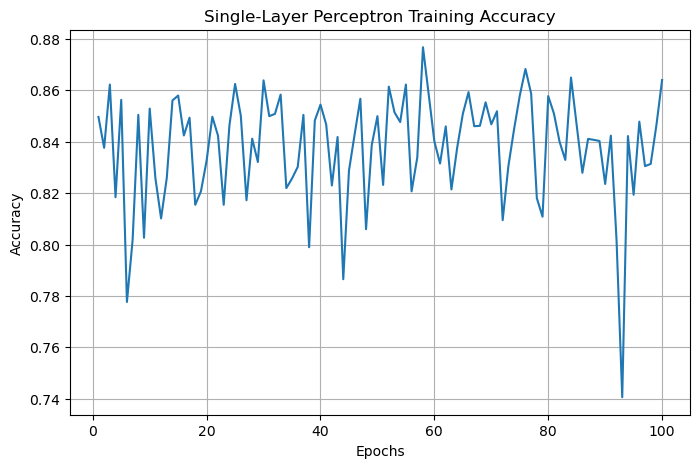

In [28]:
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(model.accuracy_history) + 1),
    model.accuracy_history
)
plt.title("Single-Layer Perceptron Training Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.grid(True)
plt.show()

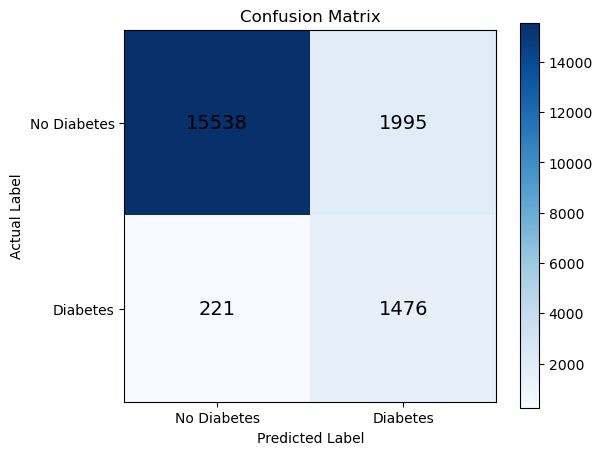

In [29]:
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(
    [0, 1],
    ["No Diabetes", "Diabetes"]
)
plt.yticks(
    [0, 1],
    ["No Diabetes", "Diabetes"]
)
for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center",
            fontsize=14
        )
plt.colorbar()
Splt.show()

In [30]:
results = pd.DataFrame({
    "Performance Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],

    "Score": [
        accuracy,
        precision,
        recall,
        f1_score
    ]
})
print("FINAL MODEL PERFORMANCE")
display(results)
print("\nProject Details:")
print("Dataset: Diabetes Prediction Dataset")
print("Model: Single-Layer Perceptron")
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Input Features:", X_train.shape[1])
print("Testing Accuracy:", round(accuracy, 4))

FINAL MODEL PERFORMANCE


,Performance Metric,Score
0,Accuracy,0.884763
1,Precision,0.425238
2,Recall,0.869770
3,F1 Score,0.571207



Project Details:
Dataset: Diabetes Prediction Dataset
Model: Single-Layer Perceptron
Training Samples: 13570
Testing Samples: 19230
Input Features: 15
Testing Accuracy: 0.8848


In [32]:
results.to_csv(
    "ANN_Performance_Results.csv",
    index=False
)
print("Performance results saved successfully")

Performance results saved successfully
